In [2]:
!pip install pandas 
!pip install numpy 
!pip install matplotlib 
!pip install sqlalchemy 
!pip install faker

     ---------------------------------------- 2.0/2.0 MB 9.1 MB/s eta 0:00:00
     ------------------------------------- 349.0/349.0 kB 10.9 MB/s eta 0:00:00


In [3]:
import pandas as pd
import numpy as np
import random
from faker import Faker
from sqlalchemy import create_engine
import matplotlib.pyplot as plt

In [4]:
## Generate CRM Data (Customers)
fake = Faker()

customers = []
for i in range(100):
    customers.append({
        "customer_id": i,
        "name": fake.name(),
        "city": fake.city(),
        "email": fake.email()
    })

customers_df = pd.DataFrame(customers)
customers_df.head()


,customer_id,name,city,email
0,0,Christopher Freeman,Sarahside,garciakristen@example.net
1,1,Daniel Richardson,Lake Edwardfort,thomasfarrell@example.net
2,2,Mark Booth,Victoriaville,porterdanielle@example.org
3,3,Tamara Hansen,Amyburgh,aewing@example.org
4,4,Alexander Sweeney,East Alisonhaven,marquezjoshua@example.com


In [5]:
# Products
products = []
for i in range(20):
    products.append({
        "product_id": i,
        "product_name": fake.word(),
        "price": round(random.uniform(10, 500), 2)
    })

products_df = pd.DataFrame(products)

# Orders
orders = []
for i in range(300):
    orders.append({
        "order_id": i,
        "customer_id": random.randint(0, 99),
        "product_id": random.randint(0, 19),
        "quantity": random.randint(1, 5)
    })


In [6]:
orders_df = pd.DataFrame(orders)

orders_df.head()


,order_id,customer_id,product_id,quantity
0,0,76,14,5
1,1,40,8,4
2,2,87,2,3
3,3,44,3,4
4,4,38,12,5


In [7]:
# Store Data in Database 
engine = create_engine("sqlite:///erp_crm.db")

customers_df.to_sql("customers", engine, if_exists="replace", index=False)
products_df.to_sql("products", engine, if_exists="replace", index=False)
orders_df.to_sql("orders", engine, if_exists="replace", index=False)

print("Database created successfully!")


Database created successfully!


In [8]:
# Combine Data (Business View)
df = orders_df.merge(customers_df, on="customer_id") \
              .merge(products_df, on="product_id")

df["revenue"] = df["quantity"] * df["price"]

df.head()


,order_id,customer_id,product_id,quantity,name,city,email,product_name,price,revenue
0,0,76,14,5,Bridget Scott,Jenniferview,mwilliams@example.net,take,245.51,1227.55
1,279,87,14,2,Ray Silva,Warrenchester,wanthony@example.com,take,245.51,491.02
2,136,7,14,1,Alexandra Mccoy,Contrerasview,tolson@example.com,take,245.51,245.51
3,21,66,14,3,Shannon Knight,Heidimouth,matacarla@example.com,take,245.51,736.53
4,29,67,14,5,Joseph Cortez,West Christopherchester,danalong@example.net,take,245.51,1227.55


In [9]:
# KPI Dashboard Logic
total_revenue = df["revenue"].sum()
print("Total Revenue:", total_revenue)

top_customers = df.groupby("name")["revenue"].sum() \
                  .sort_values(ascending=False).head(5)

top_products = df.groupby("product_name")["revenue"].sum() \
                 .sort_values(ascending=False).head(5)

top_customers


Total Revenue: 272405.76


name
Ashley Kane          6906.80
Julian Bell          6787.24
Richard Moore        6226.99
Daniel Stephenson    6098.40
Kathryn Davis        6050.15
Name: revenue, dtype: float64

In [10]:
# top_products 
top_products 


product_name
community    29415.28
fund         25716.69
bad          25624.40
mouth        19639.24
ever         17697.68
Name: revenue, dtype: float64

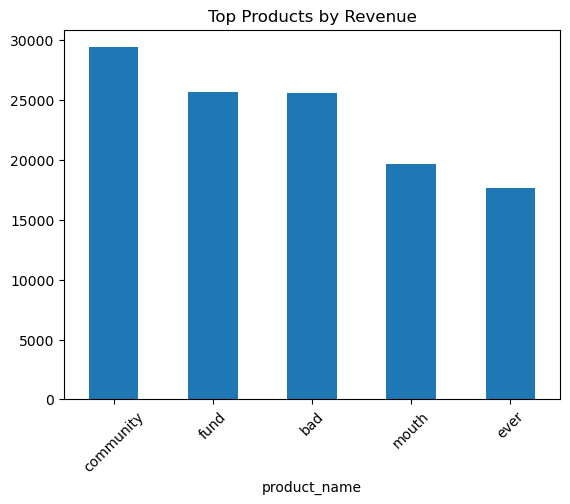

In [11]:
# Visualizations
top_products.plot(kind="bar")
plt.title("Top Products by Revenue")
plt.xticks(rotation=45)
plt.show()


In [12]:
#Add Customer Segmentation
df.groupby("city")["revenue"].sum().sort_values(ascending=False).head(10)


city
North Isaac            6906.80
East Tonya             6787.24
Greenton               6226.99
Monicaton              6098.40
Banksmouth             6050.15
Contrerasview          5734.36
East Autumn            5727.68
East Janiceton         5523.08
West Anthonyborough    5310.50
South Kathryn          5249.17
Name: revenue, dtype: float64

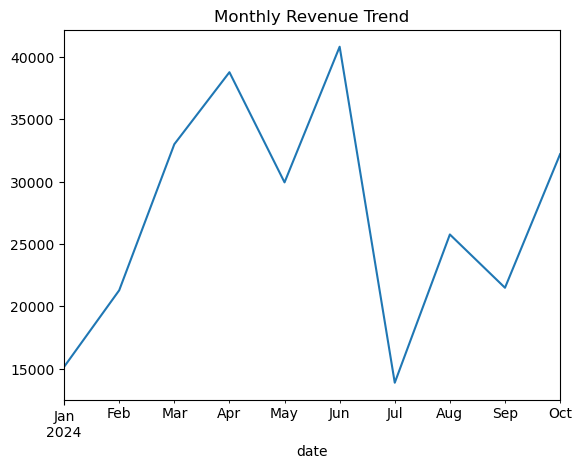

In [13]:
df["date"] = pd.date_range(start="2024-01-01", periods=len(df))
df.set_index("date")["revenue"].resample("M").sum().plot()
plt.title("Monthly Revenue Trend")
plt.show()


In [14]:
#Export to CSV (for Microsoft Power BI)
df.to_csv("final_dataset.csv", index=False)


In [14]:
df = pd.read_csv("final_dataset.csv")